![Banner](../images/09_11_banner_rs_foundation_models.png)

# Change and Similarity in Embedding Space

If an encoder maps similar places to nearby vectors, then a place that changed should move in
embedding space, and places that look alike should sit close together wherever they are. This
notebook uses both ideas. It maps the 2026 Bug Fire in California from the change between pre-fire
and post-fire Sentinel-2 embeddings and scores the result against the fire perimeter and the
differenced Normalized Burn Ratio (dNBR). It follows seven years of river migration in the
Bangladesh delta with Landsat embeddings. It then searches a whole scene for every place that looks
like one example.

## Overview

### Change as distance between embeddings

Classical change detection compares band values or indices between two dates: dNBR for fires,
NDWI for water, NDVI for vegetation. Each index targets one kind of change and responds to
everything that changes its bands, including illumination, phenology and haze. Embedding change
compares what an encoder sees in a patch, so it responds to changes in structure and texture as well
as colour, for any kind of change at once. `fm.embedding_change` returns 1 minus the cosine similarity
of the two embeddings in every cell: 0 means no change, larger values mean more change.

### One normalization for both dates

Change detection only works if both dates are prepared identically. Standardizing each scene by its
own mean and standard deviation removes exactly what a fire changes, the overall brightness of the
bands, so the statistics of one date (or the model's fixed statistics) must be applied to both.

### Thresholds and false alarms

A change map is continuous; a burned area map needs a threshold. The receiver operating
characteristic (ROC) curve and its area (AUC) score the map without choosing one. False alarms come
from clouds and shadows, seasonal change in vegetation, and changes the encoder notices that the
reference does not record.

### Similarity search

An index of embeddings is an archive searchable by example: give one patch, get every patch that
looks like it. `fm.similarity_map` scores every cell of a map against a query, and
`fm.embedding_search` returns the nearest rows of any index. For millions of chips, approximate
nearest-neighbour libraries (FAISS, Annoy) replace the exact search used here.

## Change and Similarity with GeoLattice

| Task | GeoLattice |
|---|---|
| patch features of each date | `enc.embed_raster(da, dense=True, norm={"method": "standard", "mean": m, "std": s})` |
| change map | `fm.embedding_change(before, after)` |
| burn index | dNBR from the NBR of each date |
| similarity to an example | `fm.similarity_map(emb, query)` |
| nearest neighbours | `fm.embedding_search(index, query, k=)` |

### Learning objectives

1. Prepare two dates with one normalization and embed them with two encoders.
2. Map change with `fm.embedding_change` and compare it with dNBR.
3. Score change maps against a fire perimeter with ROC curves.
4. Show what separate per-date standardization does to a change map.
5. Follow change through a seven-scene Landsat series.
6. Search a scene for every place that looks like one example.

### Data

| Dataset | Content |
|---|---|
| Bug Fire, California | Sentinel-2 L2A tile 10TGK, the clearest scenes before (July to early August) and after (September 2026) the fire; NIFC perimeter |
| Bangladesh delta | Landsat 8 Collection 2 Level-2, path 137 row 45, dry season 2013 to 2020 (seven scenes; green, red, NIR) |

### Contents

- Setup
- Before and after the Bug Fire
- dNBR, the reference index
- Embeddings of both dates
- Scoring change maps against the perimeter
- What separate normalization does
- Seven years of a delta
- Searching a scene with one example
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

import geopandas as gpd  # fire perimeter
from rasterio.features import rasterize  # perimeter to grid
from sklearn.metrics import roc_auc_score, roc_curve  # scores
FIRE = CAP / "bug_fire_sentinel2"  # Bug Fire scenes and perimeter
DELTA = CAP / "bd_delta_annual"  # Bangladesh delta Landsat scenes
S2_BANDS = ["blue", "green", "red", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]  # bands on disk

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Before and after the Bug Fire

Both scenes are tile 10TGK: the clearest July or early August scene before the fire and the clearest
September scene after it, chosen by the cloud cover recorded in each scene's metadata. Sentinel-2
stores some bands at 10 m and others at 20 m, so every band is put on the 10 m grid before stacking.
The Planetary Computer files hold digital numbers of processing baseline 05.12, which carry an offset
of 1000: reflectance is `(DN - 1000) / 10000`. The scene classification layer (SCL) masks clouds,
cirrus and snow, but not "cloud shadow": its classifier often labels fresh burn scars as shadow, and
masking them would remove the fire. The area around the perimeter (with a 3 km margin) is averaged
to 20 m to keep the arrays small.

20260806 -> 20260907 | {'band': 9, 'y': 1600, 'x': 1482} | masked before / after: 0.0% / 0.0%


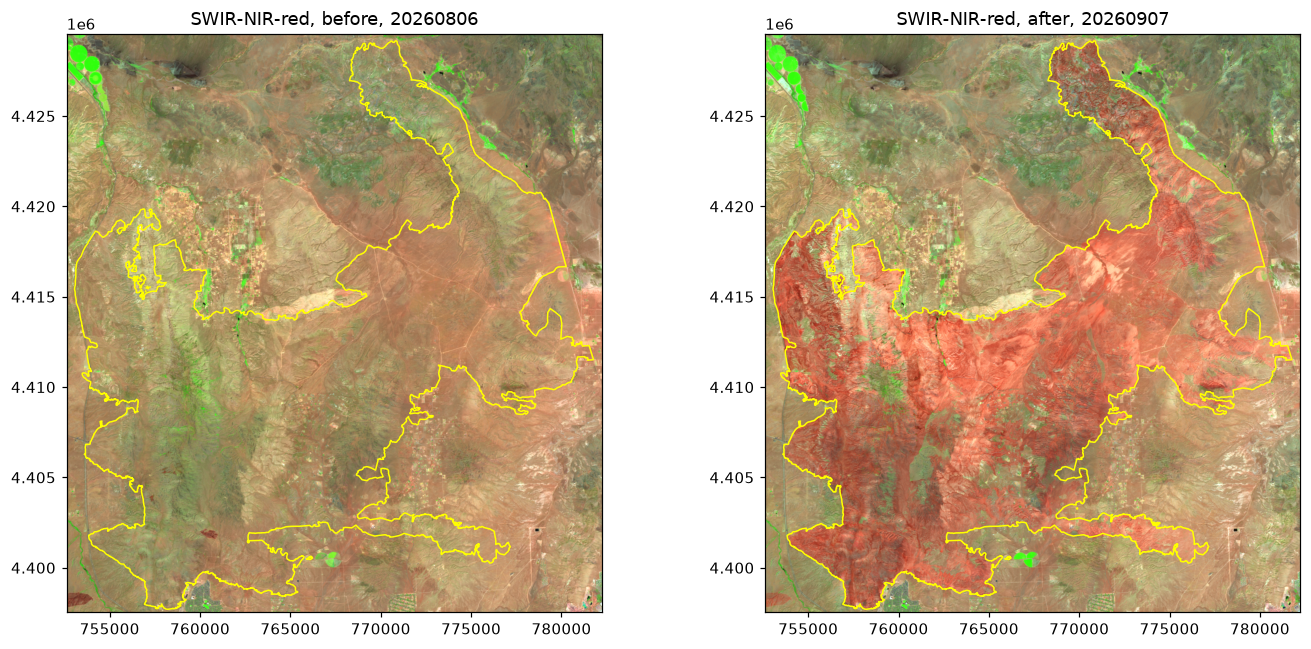

In [2]:
perim = gpd.read_file(FIRE / "bug_fire_perimeter.geojson").to_crs(32610)  # NIFC perimeter, UTM 10N
perim["geometry"] = perim.geometry.buffer(0)  # repair self-intersections in the drawn perimeter
xmin, ymin, xmax, ymax = perim.total_bounds + np.array([-3000, -3000, 3000, 3000])  # 3 km margin


def clearest(folder, after=None):  # 10TGK scene with the lowest cloud cover (optionally after a date)
    import json  # scene metadata
    scenes = [d for d in (FIRE / folder).glob("*T10TGK*") if after is None or d.name[11:19] >= after]  # candidates
    cc = {d: json.loads((d / "item.json").read_text())["properties"]["eo:cloud_cover"] for d in scenes}  # cloud cover
    return min(cc, key=cc.get)  # the clearest


def read_s2(d):  # 9-band reflectance at 20 m around the fire, clouds masked
    ref = rioxarray.open_rasterio(d / "red.tif").squeeze("band", drop=True).rio.clip_box(xmin, ymin, xmax, ymax)  # 10 m grid
    layers = []  # one layer per band
    for b in S2_BANDS:  # every band (10 m or 20 m on disk)
        a = rioxarray.open_rasterio(d / f"{b}.tif").squeeze("band", drop=True)  # band
        layers.append(a.rio.reproject_match(ref, resampling=0))  # every band on the same 10 m grid
    arr = xr.concat(layers, dim=pd.Index(S2_BANDS, name="band"))  # (9, y, x)
    arr = (arr.astype("float32") - 1000) / 10000  # baseline 05.12 offset and scale
    scl = rioxarray.open_rasterio(d / "scl.tif").squeeze("band", drop=True).rio.reproject_match(ref, resampling=0)  # scene classes
    arr = arr.where(~scl.isin([0, 1, 8, 9, 10, 11]))  # drop no data, saturated, cloud, cirrus, snow (keep class 3: burn scars are often labelled shadow)
    return arr.coarsen(y=2, x=2, boundary="trim").mean().rio.write_crs(32610), d.name[11:19]  # 20 m, and the date


pre, d_pre = read_s2(clearest("pre")); post, d_post = read_s2(clearest("post", after="20260901"))  # clearest dates
post = post.assign_coords(x=pre.x, y=pre.y)  # identical grids
print(d_pre, "->", d_post, "|", dict(pre.sizes), "| masked before / after:",
      f"{float(pre.isnull().any('band').mean()):.1%} / {float(post.isnull().any('band').mean()):.1%}")  # summary

ext = [float(pre.x.min()), float(pre.x.max()), float(pre.y.min()), float(pre.y.max())]  # map extent
swir = lambda a: np.clip(np.nan_to_num(a.sel(band=["swir22", "nir08", "red"]).transpose("y", "x", "band").values) / 0.4, 0, 1)  # SWIR false colour
fig, ax = plt.subplots(1, 2, figsize=(13, 6))  # before and after
for a, (t, da) in zip(ax, {f"before, {d_pre}": pre, f"after, {d_post}": post}.items()):  # two dates
    a.imshow(swir(da), extent=ext); perim.boundary.plot(ax=a, color="yellow", lw=1); a.set_title(f"SWIR-NIR-red, {t}")  # map
plt.tight_layout(); plt.show()  # draw

In the SWIR-NIR-red composite healthy vegetation is green and fresh burn scars are dark red-brown.
The burn scar fills most of the perimeter, with unburned islands inside it.

## dNBR, the reference index

The Normalized Burn Ratio uses NIR and SWIR 2; its difference before minus after (dNBR) is the
standard burn severity index (Key and Benson 2006). Values above about 0.1 indicate burning.

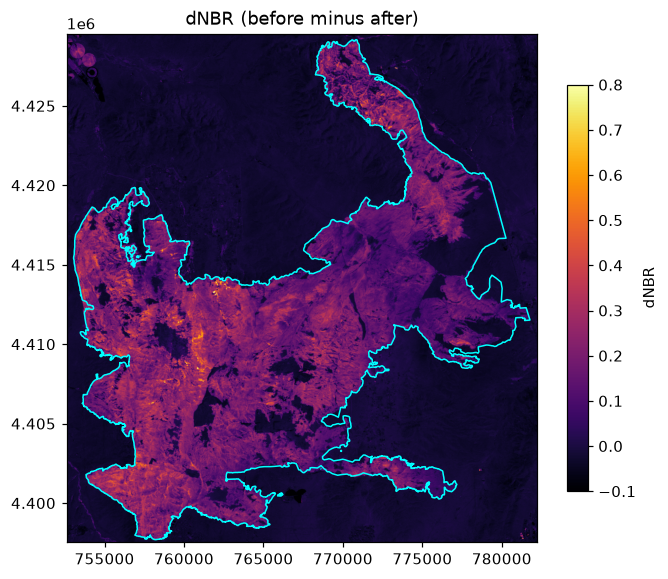

In [3]:
nbr = lambda a: (a.sel(band="nir08") - a.sel(band="swir22")) / (a.sel(band="nir08") + a.sel(band="swir22"))  # NBR
dnbr = nbr(pre) - nbr(post)  # dNBR, positive = burned
fig, ax = plt.subplots(figsize=(7, 6))  # one panel
im = ax.imshow(dnbr, cmap="inferno", vmin=-0.1, vmax=0.8, extent=ext); perim.boundary.plot(ax=ax, color="cyan", lw=1)  # map
plt.colorbar(im, ax=ax, shrink=0.8, label="dNBR"); ax.set_title("dNBR (before minus after)"); plt.show()  # draw

## Embeddings of both dates

Two encoders read both dates: DOFA (wavelength-aware, nine bands) and the SSL4EO ViT-S (thirteen
bands, the four missing ones filled from neighbours). For DOFA the per-band mean and standard
deviation of the **before** scene standardize both dates; SSL4EO has fixed statistics, so
`norm="model"` is already identical for both.

The scene is embedded in **overlapping chips**: 32 pixels (640 m) wide, every 16 pixels (320 m), each
resized to the model's 224 pixel input and pooled to one vector. A first version of this notebook
used patch features of 224 pixel chips (`dense=True`); DOFA's change map was then dominated by bright
lines along chip borders, where a patch sees less context and its features change most between two
images. Overlapping pooled chips give every cell the same context on both dates. Masked (cloudy)
pixels are filled with the scene mean for the encoder, and chips more than 10 % masked on either date
are left out of the maps and the scores.

In [4]:
CH, ST = 32, 16  # chip size and stride in 20 m pixels (640 m chips every 320 m)


def chip_mean(field):  # mean of a 2-D field in the same overlapping chips -> (rows, cols), ys, xs
    c, ys, xs = fm.chip_raster(field.expand_dims(band=["v"]).astype("float32"), chip_size=CH, stride=ST)  # chips
    return np.nanmean(c[:, 0].reshape(len(c), -1), 1).reshape(len(ys), len(xs)), ys, xs  # chip means


masked, ys, xs = chip_mean((pre.isnull().any("band") | post.isnull().any("band")).astype("float32"))  # masked share per chip
usable = masked <= 0.10  # chips clear enough on both dates
mu = pre.mean(("y", "x")).values; sd = pre.std(("y", "x")).values  # statistics of the before scene
fixed = {"method": "standard", "mean": mu, "std": sd}  # one normalization for both dates
fill = pre.mean(("y", "x"))  # value for masked pixels
emb = {}  # embeddings per model and date
t0 = time.perf_counter()  # start the clock
dofa = fm.load_model("dofa-base", device=DEVICE)  # DOFA
for k, da in {"pre": pre, "post": post}.items():  # both dates
    emb[("DOFA", k)] = dofa.embed_raster(da.fillna(fill), chip_size=CH, stride=ST, norm=fixed, batch_size=128)  # (768, rows, cols)
del dofa
ssl = fm.load_model("ssl4eo-s12-vits16-dino", device=DEVICE)  # SSL4EO ViT-S, DINO
for k, da in {"pre": pre, "post": post}.items():  # both dates
    emb[("SSL4EO", k)] = ssl.embed_raster(da.fillna(fill), chip_size=CH, stride=ST, norm="model", batch_size=128)  # (384, rows, cols)
del ssl; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
change = {m: fm.embedding_change(emb[(m, "pre")], emb[(m, "post")]).where(usable) for m in ["DOFA", "SSL4EO"]}  # 1 - cosine, clear chips
print(f"{usable.size} chips, {usable.mean():.0%} clear on both dates | {time.perf_counter() - t0:.0f} s")  # summary

9108 chips, 100% clear on both dates | 241 s


dNBR is averaged over exactly the same chips, and a chip counts as inside the fire when its centre is
inside the perimeter.

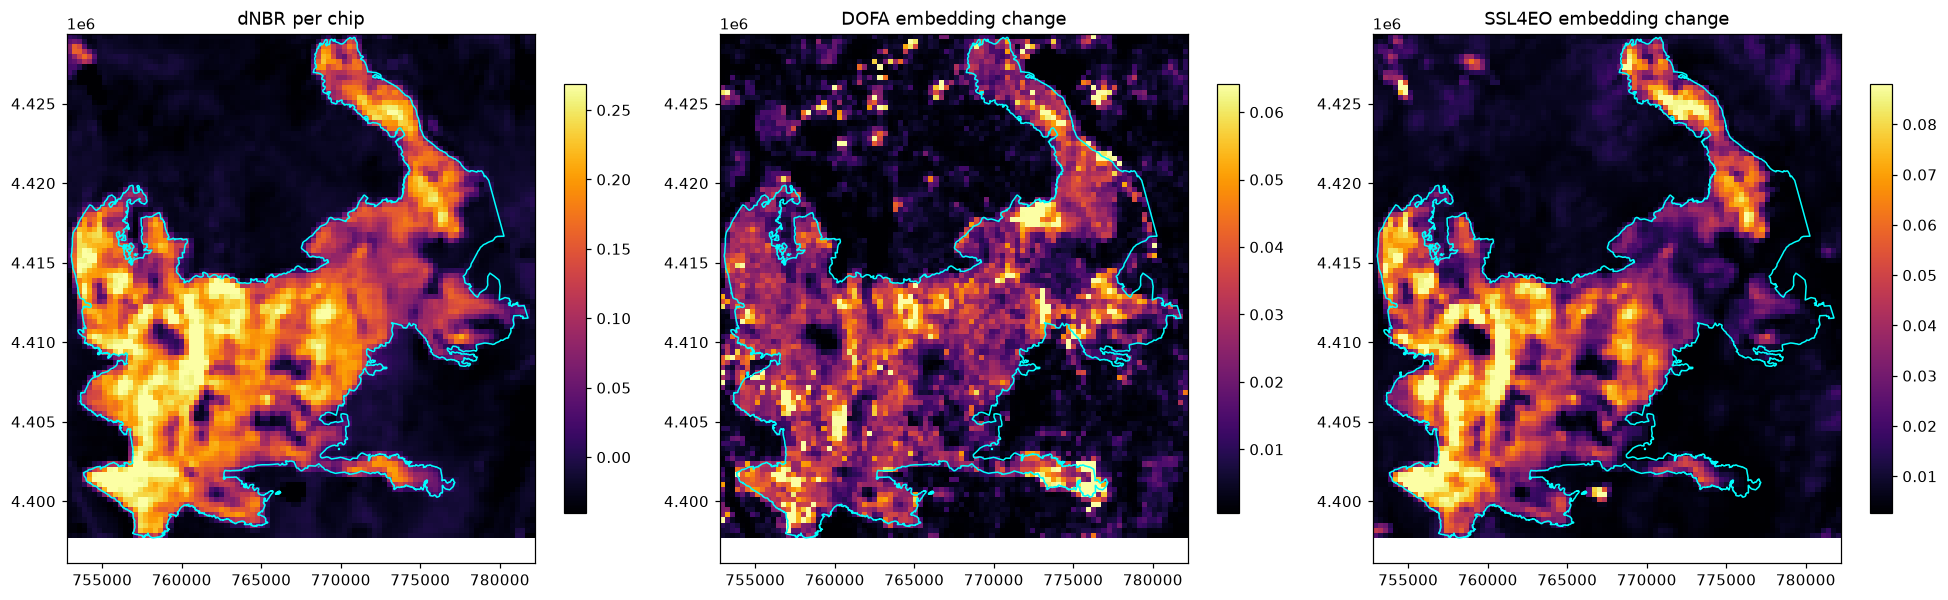

In [5]:
dn = np.where(usable, chip_mean(dnbr)[0], np.nan)  # dNBR per chip
yy, xx = np.meshgrid(ys, xs, indexing="ij")  # chip centres
inside = gpd.points_from_xy(xx.ravel(), yy.ravel(), crs=32610).within(perim.union_all()).reshape(yy.shape)  # centre inside the perimeter
cext = [xs.min() - 160, xs.max() + 160, ys.min() - 160, ys.max() + 160]  # extent of the chip grid

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))  # three change maps
for a, (t, v) in zip(ax, {"dNBR per chip": dn, "DOFA embedding change": change["DOFA"].values,
                          "SSL4EO embedding change": change["SSL4EO"].values}.items()):  # every map
    im = a.imshow(v, cmap="inferno", extent=cext, vmin=np.nanpercentile(v, 2), vmax=np.nanpercentile(v, 98))  # map
    perim.boundary.plot(ax=a, color="cyan", lw=1); a.set_title(t); plt.colorbar(im, ax=a, shrink=0.75)  # perimeter and scale
plt.tight_layout(); plt.show()  # draw

The three maps agree on the burn scar: a large burned area in the west and south and a narrower
arm running north-east. The SSL4EO change map is almost a smoothed copy of dNBR (correlation about
0.90 over all chips). The DOFA map shows the same scar with more chip-to-chip noise and some isolated
bright chips outside it (correlation about 0.55). Neither encoder was told anything about fire: the
change is simply what moved most in their embedding spaces between the two dates.

## Scoring change maps against the perimeter

The perimeter is an imperfect reference (it includes unburned islands and is drawn from aerial
surveys), but it is independent of all three maps. ROC curves show how well each map separates chips
inside from chips outside at every threshold.

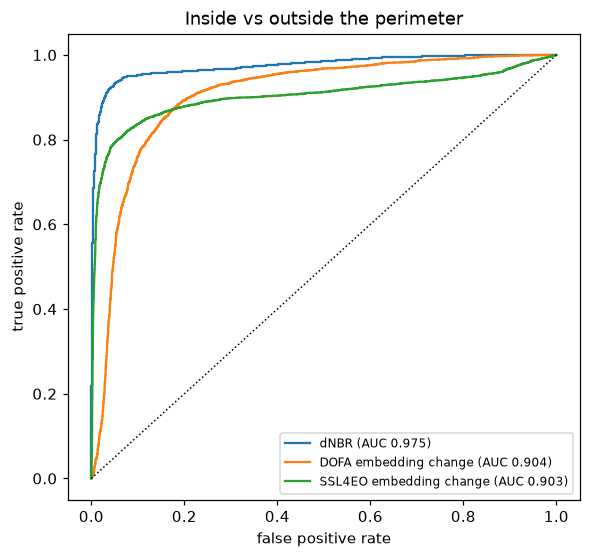

9108 clear chips | correlation with dNBR: {'DOFA embedding change': np.float64(0.554), 'SSL4EO embedding change': np.float64(0.902)}


In [6]:
ok = np.isfinite(dn) & np.isfinite(change["DOFA"].values) & np.isfinite(change["SSL4EO"].values)  # clear chips
maps = {"dNBR": dn, "DOFA embedding change": change["DOFA"].values, "SSL4EO embedding change": change["SSL4EO"].values}  # scores
fig, ax = plt.subplots(figsize=(6, 5.5))  # ROC panel
auc = {}  # areas under the curve
for n, v in maps.items():  # every map
    fpr, tpr, _ = roc_curve(inside[ok], v[ok]); auc[n] = roc_auc_score(inside[ok], v[ok])  # ROC
    ax.plot(fpr, tpr, label=f"{n} (AUC {auc[n]:.3f})")  # curve
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")  # axes
ax.legend(fontsize=8); ax.set_title("Inside vs outside the perimeter"); plt.show()  # draw
print(ok.sum(), "clear chips | correlation with dNBR:", {n: round(np.corrcoef(dn[ok], v[ok])[0, 1], 3) for n, v in maps.items() if n != "dNBR"})  # agreement

dNBR, the index designed for burned areas, separates chips inside the perimeter best (AUC about
0.975). Both embedding change maps reach about 0.90, a good score for a generic signal that knows
nothing about fire. They trade off differently: SSL4EO finds most burned chips at very low false alarm
rates, then levels off, while DOFA needs more false alarms to find the first burned chips but catches
more of the rest. Where a dedicated index exists, it remains the better tool for its own kind of change.
Embedding change earns its place for change that no single index describes.

## What separate normalization does

The DOFA change map is recomputed with each date standardized by its own statistics, the default of
`embed_raster`. The fire darkens the after-scene in NIR and brightens it in SWIR, and per-date
standardization removes part of exactly that signal.

In [7]:
dofa = fm.load_model("dofa-base", device=DEVICE)  # DOFA again
own = {k: dofa.embed_raster(da.fillna(da.mean(("y", "x"))), chip_size=CH, stride=ST, batch_size=128)
       for k, da in {"pre": pre, "post": post}.items()}  # per-date statistics
del dofa; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
c_own = fm.embedding_change(own["pre"], own["post"]).values  # change map
pd.DataFrame({"AUC vs perimeter": {"one normalization for both dates": auc["DOFA embedding change"],
                                   "each date standardized separately": roc_auc_score(inside[ok], c_own[ok])}}).round(3)  # comparison

,AUC vs perimeter
one normalization for both dates,0.904
each date standardized separately,0.723


Standardizing each date by its own statistics drops DOFA's AUC from about 0.90 to about 0.72. The
fire changed the band statistics of the whole after-scene, and separate standardization subtracted
much of that change before the encoder saw it. One normalization for both dates is not optional.

## Seven years of a delta

The Bangladesh delta changes every year as rivers move and new land (char) forms and erodes. Seven
dry-season Landsat 8 scenes of path 137 row 45 (2013 to 2020; there is no 2016 scene on disk) have only
green, red and NIR bands; DOFA reads those three by wavelength. The scenes cover only part of their
grid, so the analysis uses the largest window, 600 pixels (18 km) tall, that has data in every year.
All years share the statistics of 2013, and the overlapping chips are 32 pixels (960 m) every 16
pixels (480 m).

years: ['2013', '2014', '2015', '2017', '2018', '2019', '2020'] | window 600 x 975 pixels (18 x 29 km)


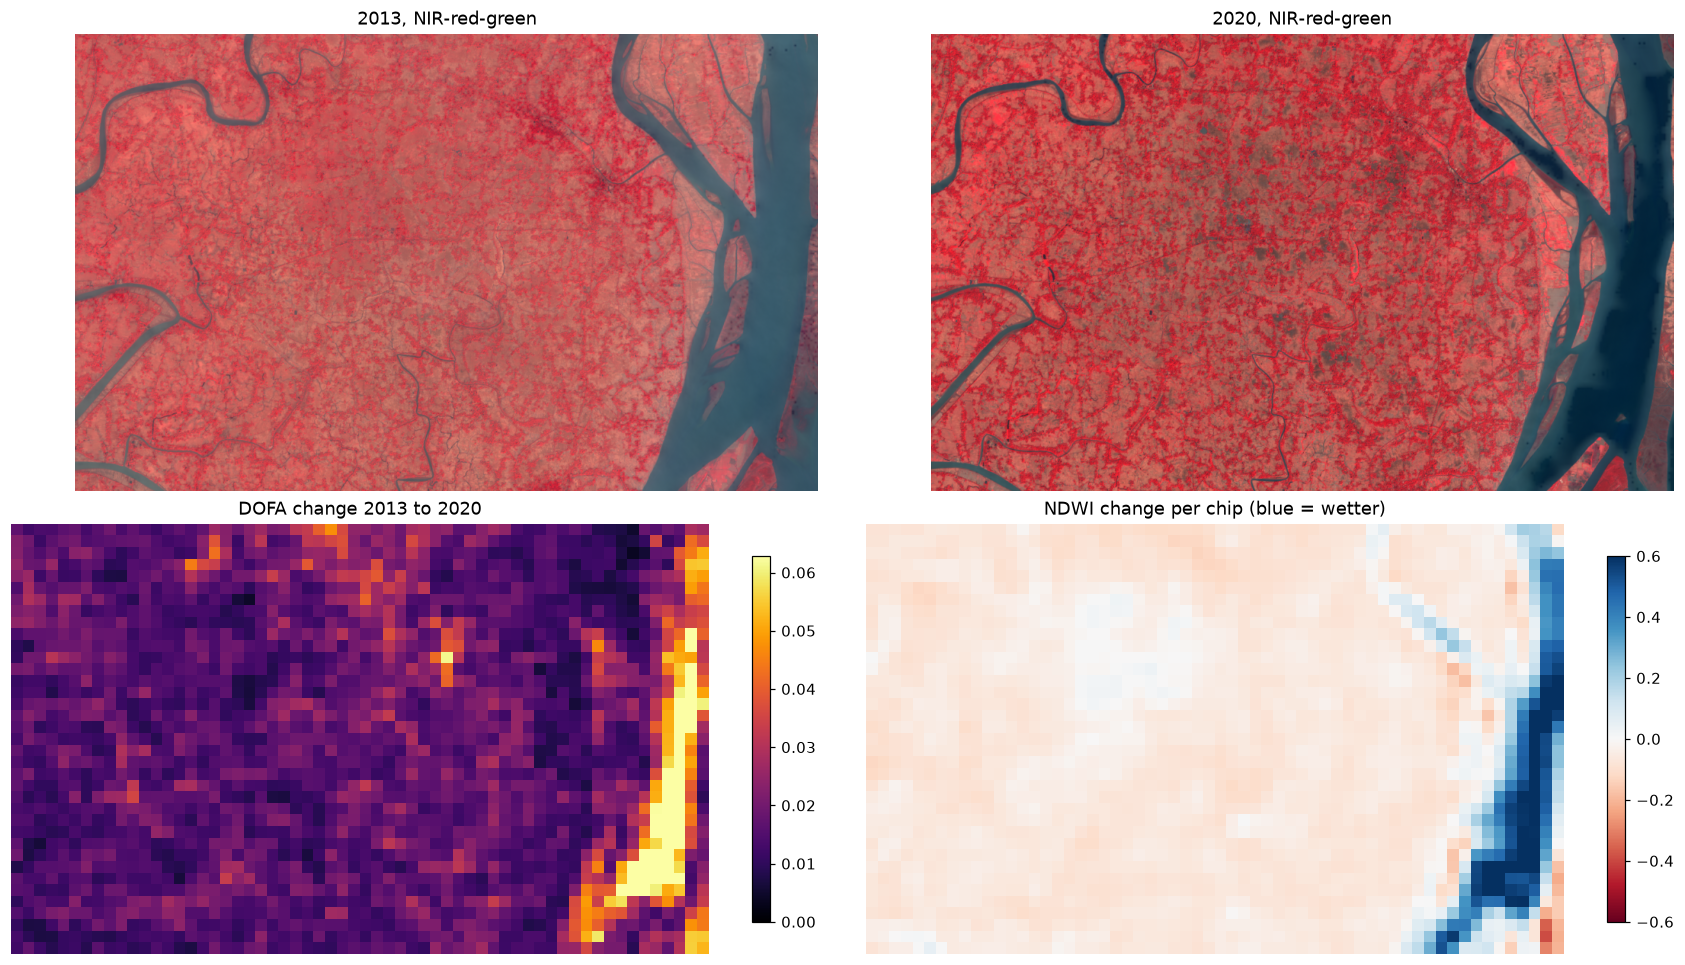

correlation of embedding change with |NDWI change|: 0.809


In [8]:
years = sorted(DELTA.glob("LC08_L2SP_137045_20*"))  # path 137 row 45 scenes
L_BANDS = ["green", "red", "nir"]  # bands on disk
names_l = {"green": "green", "red": "red", "nir": "nir08"}  # OLI NIR is 865 nm


def read_ls(d):  # Landsat reflectance, 3 bands
    a = xr.concat([rioxarray.open_rasterio(d / f"{b}.tif", masked=True).squeeze("band", drop=True) for b in L_BANDS],
                  dim=pd.Index([names_l[b] for b in L_BANDS], name="band"))  # bands
    return (a * 0.0000275 - 0.2).rio.write_crs(a.rio.crs)  # Collection 2 scale and offset


stack = [read_ls(d) for d in years]  # one array per year
ref = stack[0]  # 2013 grid
stack = [a.rio.reproject_match(ref).assign_coords(x=ref.x, y=ref.y) for a in stack]  # identical grids
labels = [d.name[17:21] for d in years]  # years
valid = np.logical_and.reduce([np.isfinite(a.values).all(0) for a in stack])  # data in every year
H = 600  # window height in pixels
best = (0, 0, 0)  # (width, first row, first column)
for r0 in range(0, valid.shape[0] - H, 10):  # slide the window down
    cols = valid[r0:r0 + H].all(0)  # columns with data on every row
    runs = np.diff(np.r_[0, cols.astype(int), 0]); starts, ends = np.flatnonzero(runs == 1), np.flatnonzero(runs == -1)  # runs of True
    if len(starts) and (ends - starts).max() > best[0]:  # widest so far
        i = np.argmax(ends - starts); best = ((ends - starts)[i], r0, starts[i])  # record it
w, r0, c0 = best  # the window
stack = [a.isel(y=slice(r0, r0 + H), x=slice(c0, c0 + w)) for a in stack]  # crop every year
print("years:", labels, f"| window {H} x {w} pixels ({H * 0.03:.0f} x {w * 0.03:.0f} km)")  # summary

mu, sd = stack[0].mean(("y", "x")).values, stack[0].std(("y", "x")).values  # 2013 statistics
dofa = fm.load_model("dofa-base", device=DEVICE)  # DOFA
E = [dofa.embed_raster(a, chip_size=CH, stride=ST, batch_size=128, norm={"method": "standard", "mean": mu, "std": sd})
     for a in stack]  # one map per year
del dofa; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
yearly = np.stack([fm.embedding_change(E[i], E[i + 1]).values for i in range(len(E) - 1)])  # change between consecutive years
total = fm.embedding_change(E[0], E[-1])  # first to last year
ndwi = lambda a: (a.sel(band="green") - a.sel(band="nir08")) / (a.sel(band="green") + a.sel(band="nir08"))  # water index
dw = chip_mean(ndwi(stack[-1]) - ndwi(stack[0]))[0]  # NDWI change per chip

fig, ax = plt.subplots(2, 2, figsize=(16, 9))  # four panels
fc = lambda a: np.clip(np.nan_to_num(a.sel(band=["nir08", "red", "green"]).transpose("y", "x", "band").values) / 0.3, 0, 1)  # NIR false colour
ax[0, 0].imshow(fc(stack[0])); ax[0, 0].set_title(f"{labels[0]}, NIR-red-green")  # first year
ax[0, 1].imshow(fc(stack[-1])); ax[0, 1].set_title(f"{labels[-1]}, NIR-red-green")  # last year
im = ax[1, 0].imshow(total, cmap="inferno", vmin=0, vmax=float(np.nanpercentile(total, 98))); ax[1, 0].set_title(f"DOFA change {labels[0]} to {labels[-1]}")  # embedding change
plt.colorbar(im, ax=ax[1, 0], shrink=0.8)  # scale
im = ax[1, 1].imshow(dw, cmap="RdBu", vmin=-0.6, vmax=0.6); ax[1, 1].set_title("NDWI change per chip (blue = wetter)"); plt.colorbar(im, ax=ax[1, 1], shrink=0.8)  # water change
for a in ax.ravel():  # all panels
    a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # draw
print("correlation of embedding change with |NDWI change|:", round(np.corrcoef(total.values.ravel(), np.abs(dw).ravel())[0, 1], 3))  # agreement

The window covers 18 x 29 km of the delta, with the lower Meghna channel on the east. Embedding
change is concentrated along the main channel, where the river shifted and new land formed, and it
follows the water index closely: the correlation between embedding change and the size of the NDWI
change is about 0.81. Part of the change in the channel is the colour of the water itself (turbid in
2013, darker and clearer in 2020), which both measures see as change. Inland, the many small paddies
and villages change little between dry seasons.

How often each chip changed strongly between consecutive years separates stable land from the
active river corridor.

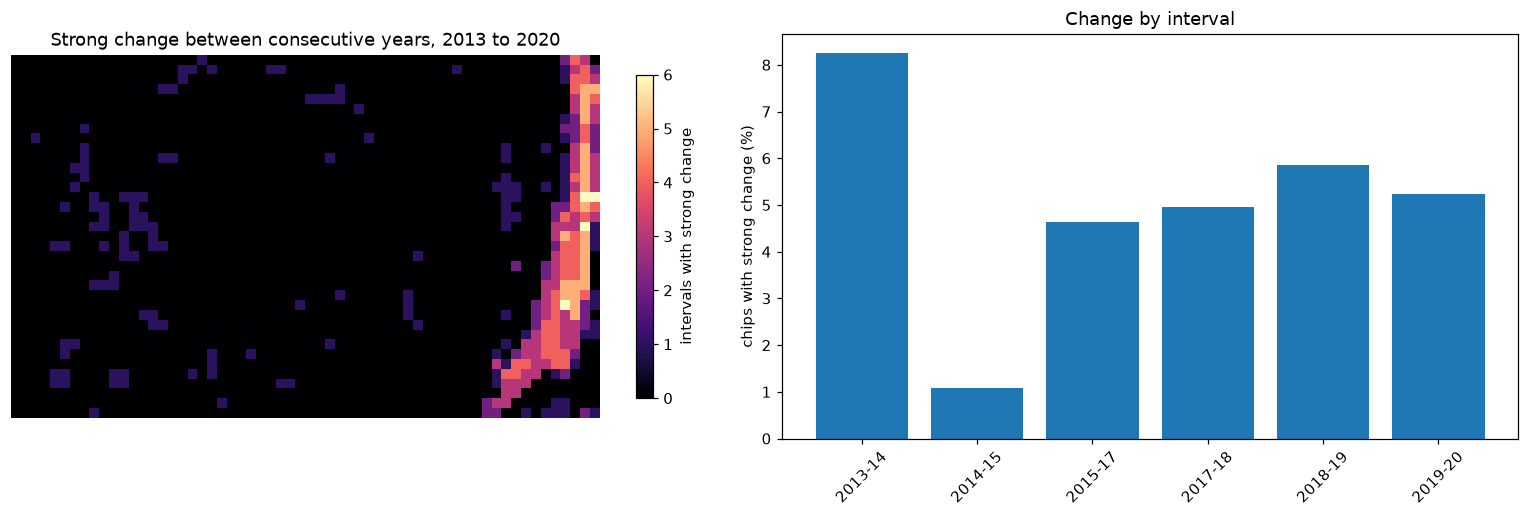

In [9]:
thr = np.nanpercentile(yearly, 95)  # "strong change": the top 5 % of all yearly changes
n_strong = (yearly > thr).sum(0)  # intervals with strong change per chip
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))  # map and bar chart
im = ax[0].imshow(n_strong, cmap="magma"); plt.colorbar(im, ax=ax[0], shrink=0.8, label="intervals with strong change"); ax[0].axis("off")  # map
ax[0].set_title(f"Strong change between consecutive years, {labels[0]} to {labels[-1]}")  # title
ax[1].bar([f"{labels[i]}-{labels[i + 1][2:]}" for i in range(len(labels) - 1)], (yearly > thr).mean((1, 2)) * 100)  # share per interval
ax[1].set_ylabel("chips with strong change (%)"); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Change by interval")  # labels
plt.tight_layout(); plt.show()  # draw

Chips with strong change in several intervals line the main channel: the active river corridor, where
banks erode and chars grow year after year. Inland, strong change is rare and isolated. Among the
intervals, 2013 to 2014 has the most strong change and 2014 to 2015 the least, which reflects
differences between acquisitions (water level, turbidity, date in the dry season) as much as change on
the ground. A change series must be read with the conditions of each image in mind.

## Searching a scene with one example

The 2020 embedding map is an index of every chip. One example chip is chosen automatically: the chip
with the brightest red reflectance among chips that contain at least 10 % water. It turns out to be a
stretch of riverbank on the main channel, part land and part water. Every chip is scored by its
similarity to it.

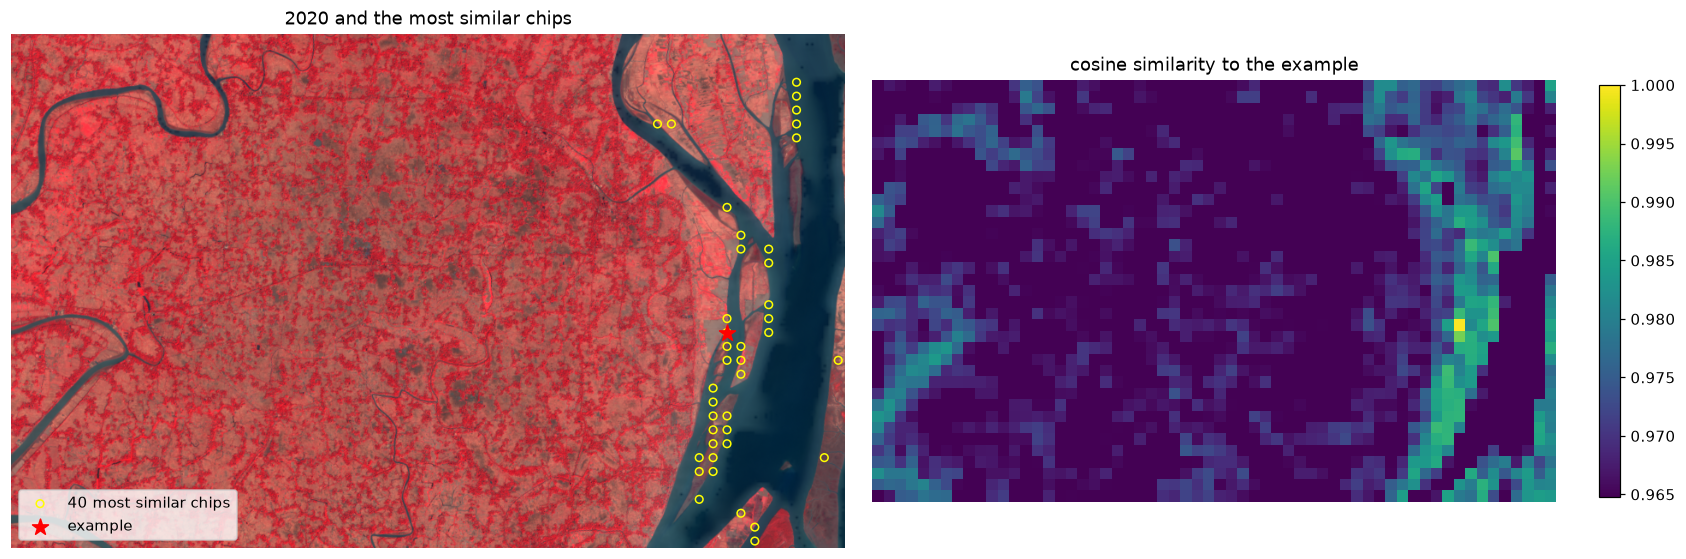

hits with water: 100% | more than 2 km away: 75% | red reflectance of hits 0.097 vs window 0.084


In [10]:
e20 = E[-1]  # 2020 embeddings
red = chip_mean(stack[-1].sel(band="red"))[0]  # red reflectance per chip
wet = chip_mean((ndwi(stack[-1]) > 0.2).astype("float32"))[0] > 0.1  # chips with at least 10 % water
iy, ix = np.unravel_index(np.nanargmax(np.where(wet, red, np.nan)), red.shape)  # brightest chip next to water
query = e20.isel(y=iy, x=ix)  # the example
sim = fm.similarity_map(e20, query)  # cosine similarity of every chip
X = e20.values.reshape(e20.sizes["embedding"], -1).T  # index (chips, D)
idx, score = fm.embedding_search(X, query.values[None], k=40)  # 40 nearest chips
hy, hx = np.unravel_index(idx[0], red.shape)  # their positions
fig, ax = plt.subplots(1, 2, figsize=(16, 5))  # map and similarity
ax[0].imshow(fc(stack[-1]), extent=[0, red.shape[1], red.shape[0], 0])  # 2020 image on the chip grid
ax[0].scatter(hx + 0.5, hy + 0.5, s=25, facecolors="none", edgecolors="yellow", label="40 most similar chips")  # hits
ax[0].scatter(ix + 0.5, iy + 0.5, s=120, marker="*", color="red", label="example"); ax[0].legend(loc="lower left")  # query
ax[0].set_title("2020 and the most similar chips"); ax[0].axis("off")  # title
im = ax[1].imshow(sim, cmap="viridis", vmin=float(np.nanpercentile(sim, 50)), vmax=1); plt.colorbar(im, ax=ax[1], shrink=0.8)  # similarity
ax[1].set_title("cosine similarity to the example"); ax[1].axis("off"); plt.tight_layout(); plt.show()  # draw
far = np.hypot(hy - iy, hx - ix) > 4  # hits more than 2 km from the example
print(f"hits with water: {wet[hy, hx].mean():.0%} | more than 2 km away: {far.mean():.0%} | "
      f"red reflectance of hits {np.nanmean(red[hy, hx]):.3f} vs window {np.nanmean(red):.3f}")  # check

The 40 most similar chips all contain water, and three quarters of them lie more than 2 km from the
example: the search found riverbanks along the whole main channel, with a few on the western channels,
and ignored the inland paddies. This is retrieval by example without any labels: one chip in, every
chip of the same kind out. The similarity values themselves are all high (above 0.96) because DOFA's
embeddings of one scene occupy a narrow cone; ranking, not the absolute value, is what matters.

## Summary and exercises

### Summary

- Embedding change (1 minus the cosine similarity of two dates) maps any kind of change at once; for
  the Bug Fire it is scored against dNBR and the perimeter with ROC curves.
- Both dates must share one normalization: the statistics of one date, or the model's fixed statistics.
  Separate per-date standardization removes part of the change signal.
- Over a seven-scene Landsat series, consecutive-year embedding change highlights the active river
  corridor of the delta, and the number of years with strong change separates stable land from
  migrating channels.
- An embedding map is a searchable index: `fm.similarity_map` and `fm.embedding_search` find every
  place that looks like one example.

### Exercises

1. Map the Bug Fire with the clearest early-September post-fire date instead. Does the change map
   depend on how soon after the fire the image was taken?
2. Choose a threshold on the DOFA change map that matches the burned area of dNBR > 0.1, and map the
   cells where the two disagree. What are they?
3. Repeat the delta analysis with path 136 row 45, which overlaps it. Do the two series agree in the overlap?
4. Use five examples of the same feature as the query (their mean embedding). Is the search more precise?
5. Install FAISS and replace `fm.embedding_search` with an IVF index for the seven years of embeddings.
   How do speed and results compare?

### References

- Key, C. H. and Benson, N. C. (2006). Landscape assessment: ground measure of severity, the Composite Burn Index, and remote sensing of severity, the Normalized Burn Ratio. USDA Forest Service RMRS-GTR-164-CD.
- Johnson, J., Douze, M. and Jegou, H. (2019). Billion-scale similarity search with GPUs (FAISS). IEEE Transactions on Big Data.
- Xiong, Z. et al. (2024). DOFA. arXiv:2403.15356.
- Wang, Y. et al. (2023). SSL4EO-S12. IEEE GRSM.